# QuickBite Food Delivery Analytics
## Data Cleaning and Exploratory Data Analysis
### Team: Data Knights | CODEGNAN Hackathon DA-07

---
> **DISCLAIMER:** All data used in this notebook is **SYNTHETIC** and generated for
> demonstration purposes only. It does not represent actual QuickBite business records.

**Datasets Used:**
- `orders.csv` — 100,000 food delivery orders
- `restaurants.csv` — 4,000 partner restaurants
- `deliveries.csv` — Delivery records for completed orders
- `customers.csv` — 20,000 customer profiles
- `feedback.csv` — Customer ratings and complaints
- `riders.csv` — 2,000 delivery riders

**Analysis Period:** January 2024 – December 2024  
**Cities:** Hyderabad, Visakhapatnam, Vijayawada


## Section 1: Setup and Data Loading

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import os
from datetime import datetime

warnings.filterwarnings('ignore')

# ── Plot styling ──────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.figsize':    (12, 5),
    'axes.titlesize':    14,
    'axes.titleweight':  'bold',
    'axes.labelsize':    11,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'figure.dpi':        110,
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'axes.spines.top':   False,
    'axes.spines.right': False,
})
PALETTE = ['#1A73E8', '#34A853', '#FBBC04', '#EA4335', '#9AA0A6', '#0D652D']
sns.set_palette(PALETTE)

# ── Paths ─────────────────────────────────────────────────────────────────────
BASE_DIR    = os.path.join(os.getcwd(), '..')  # notebook is in notebooks/
RAW_DIR     = os.path.join(BASE_DIR, 'data', 'raw')
DIRTY_DIR   = os.path.join(BASE_DIR, 'data', 'dirty')
CLEANED_DIR = os.path.join(BASE_DIR, 'data', 'cleaned')

print("Libraries loaded successfully.")
print(f"Raw data directory  : {os.path.abspath(RAW_DIR)}")
print(f"Cleaned data output : {os.path.abspath(CLEANED_DIR)}")


Libraries loaded successfully.
Raw data directory  : D:\Hackton\quickbite-analytics\data\raw
Cleaned data output : D:\Hackton\quickbite-analytics\data\cleaned


In [2]:
# Load all raw datasets
orders      = pd.read_csv(os.path.join(RAW_DIR, 'orders.csv'))
restaurants = pd.read_csv(os.path.join(RAW_DIR, 'restaurants.csv'))
deliveries  = pd.read_csv(os.path.join(RAW_DIR, 'deliveries.csv'))
customers   = pd.read_csv(os.path.join(RAW_DIR, 'customers.csv'))
feedback    = pd.read_csv(os.path.join(RAW_DIR, 'feedback.csv'))
riders      = pd.read_csv(os.path.join(RAW_DIR, 'riders.csv'))

print("Dataset sizes:")
print(f"  orders.csv      : {len(orders):>8,} rows x {orders.shape[1]} cols")
print(f"  restaurants.csv : {len(restaurants):>8,} rows x {restaurants.shape[1]} cols")
print(f"  deliveries.csv  : {len(deliveries):>8,} rows x {deliveries.shape[1]} cols")
print(f"  customers.csv   : {len(customers):>8,} rows x {customers.shape[1]} cols")
print(f"  feedback.csv    : {len(feedback):>8,} rows x {feedback.shape[1]} cols")
print(f"  riders.csv      : {len(riders):>8,} rows x {riders.shape[1]} cols")


Dataset sizes:
  orders.csv      :  100,000 rows x 10 cols
  restaurants.csv :    4,000 rows x 7 cols
  deliveries.csv  :   87,822 rows x 10 cols
  customers.csv   :   20,000 rows x 4 cols
  feedback.csv    :   70,302 rows x 7 cols
  riders.csv      :    2,000 rows x 3 cols


## Section 2: Dataset Inspection

We first inspect each dataset to understand its structure, data types,
and overall quality before cleaning.


In [3]:
# Inspect orders dataset
print("=== ORDERS DATASET ===")
print(orders.head(3).to_string())
print()
print(orders.info())


=== ORDERS DATASET ===
    order_id customer_id restaurant_id rider_id           order_time  order_value  discount  final_amount order_status cancellation_reason
0  ORD000001      C18506         R3674   RD1856  2024-10-14 20:03:00       488.61       0.0        488.61    Completed                 NaN
1  ORD000002      C18039         R0605   RD1987  2024-01-12 21:02:00       504.17     107.8        396.37    Completed                 NaN
2  ORD000003      C13123         R3522   RD0792  2024-03-16 23:28:00       437.84       0.0        437.84    Completed                 NaN

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             100000 non-null  str    
 1   customer_id          100000 non-null  str    
 2   restaurant_id        100000 non-null  str    
 3   rider_id             100000 non-null  str    
 4   order_time

In [4]:
print("=== RESTAURANTS DATASET ===")
print(restaurants.head(3).to_string())
print()
print(restaurants.describe())


=== RESTAURANTS DATASET ===
  restaurant_id            restaurant_name        cuisine          area           city  avg_prep_time  restaurant_rating
0         R0001         Grand Burger Bites         Burger      Ameerpet      Hyderabad           14.3                3.8
1         R0002         Spicy Biryani Stop        Biryani      Gunadala     Vijayawada           25.7                4.4
2         R0003  Quick Rolls & Wraps Point  Rolls & Wraps  Maddilapalem  Visakhapatnam           16.0                3.7

       avg_prep_time  restaurant_rating
count    4000.000000        4000.000000
mean       17.389450           3.902875
std         7.260265           0.499667
min         5.000000           1.900000
25%        11.900000           3.600000
50%        16.450000           3.900000
75%        22.100000           4.300000
max        48.100000           5.000000


In [5]:
print("=== DELIVERIES DATASET ===")
print(deliveries.head(3).to_string())
print()
print(deliveries.describe())


=== DELIVERIES DATASET ===
  delivery_id   order_id rider_id          pickup_time        delivery_time  distance_km  estimated_delivery_time  actual_delivery_minutes  delay_minutes on_time_status
0   DEL000001  ORD000001   RD1856  2024-10-14 20:18:04  2024-10-14 20:54:34         9.34                     37.3                     36.5           -0.8        On Time
1   DEL000002  ORD000002   RD1987  2024-01-12 21:32:46  2024-01-12 22:12:10         3.39                     44.4                     39.4           -5.0        On Time
2   DEL000003  ORD000003   RD0792  2024-03-17 00:12:09  2024-03-17 01:23:21         9.19                     67.8                     71.2            3.4        On Time

        distance_km  ...  delay_minutes
count  87822.000000  ...   87822.000000
mean       6.833209  ...       4.656145
std        3.542067  ...      12.991162
min        0.850000  ...      -5.000000
25%        4.320000  ...      -2.000000
50%        6.040000  ...       1.000000
75%        8.470

In [6]:
print("=== FEEDBACK DATASET ===")
print(feedback.head(3).to_string())
print()
print(feedback.describe())


=== FEEDBACK DATASET ===
  feedback_id   order_id customer_id  rating               review_text complaint_type  refund_amount
0    FB000001  ORD000001      C18506       2  Delivery was quite late.      Cold Food          45.92
1    FB000002  ORD000002      C18039       4  Good experience overall.            NaN           0.00
2    FB000003  ORD000003      C13123       4  Good experience overall.            NaN           0.00

             rating  refund_amount
count  70302.000000   70302.000000
mean       3.709567       4.846917
std        0.799122      29.801499
min        1.000000       0.000000
25%        3.000000       0.000000
50%        4.000000       0.000000
75%        4.000000       0.000000
max        5.000000    1029.270000


## Section 3: Data Type Validation and Conversion

Datetime columns were stored as strings in CSV. We convert them to proper
`datetime64` types for time-based analysis.


In [7]:
# Convert datetime columns
orders['order_time']         = pd.to_datetime(orders['order_time'])
deliveries['pickup_time']    = pd.to_datetime(deliveries['pickup_time'])
deliveries['delivery_time']  = pd.to_datetime(deliveries['delivery_time'])
customers['signup_date']     = pd.to_datetime(customers['signup_date'])

# Validate ratings are integers in 1-5 range
print("Feedback rating range:", feedback['rating'].min(), "–", feedback['rating'].max())
print("Invalid ratings:", (feedback['rating'].notna() & ~feedback['rating'].between(1, 5)).sum())

# Validate positive financial values
print("\nNegative order_value rows:", (orders['order_value'] < 0).sum())
print("Negative final_amount rows:", (orders['final_amount'] < 0).sum())
print("Negative discount rows:    ", (orders['discount']     < 0).sum())

print("\nData type conversion complete.")


Feedback rating range: 1 – 5
Invalid ratings: 0

Negative order_value rows: 0
Negative final_amount rows: 0
Negative discount rows:     0

Data type conversion complete.


## Section 4: Missing Value Analysis

We check for missing values in each dataset. Note that `cancellation_reason`
and `complaint_type` being empty/null is *by design* — these are only populated
for cancelled orders and complaints respectively.


In [8]:
def missing_value_report(df, name):
    """Display missing value counts and percentages."""
    miss = df.isnull().sum()
    miss = miss[miss > 0]
    if len(miss) == 0:
        print(f"{name}: No missing values found.")
        return
    pct = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({'missing_count': miss, 'missing_pct': pct})
    print(f"\n{name} — Missing Values:")
    print(report.to_string())

missing_value_report(orders,      'Orders')
missing_value_report(restaurants, 'Restaurants')
missing_value_report(deliveries,  'Deliveries')
missing_value_report(customers,   'Customers')
missing_value_report(feedback,    'Feedback')
missing_value_report(riders,      'Riders')



Orders — Missing Values:
                     missing_count  missing_pct
cancellation_reason          87822        87.82
Restaurants: No missing values found.
Deliveries: No missing values found.
Customers: No missing values found.

Feedback — Missing Values:
                missing_count  missing_pct
complaint_type          44263        62.96
Riders: No missing values found.


In [9]:
# Explanation of expected empty fields
print("Expected empty/null fields (by design):")
print(f"  orders.cancellation_reason = empty for non-cancelled: "
      f"{(orders.cancellation_reason == '').sum()} rows")
print(f"  feedback.complaint_type    = empty for no complaint:  "
      f"{(feedback.complaint_type == '').sum()} rows")
print(f"  feedback.refund_amount = 0 for no refund:             "
      f"{(feedback.refund_amount == 0).sum()} rows")


Expected empty/null fields (by design):
  orders.cancellation_reason = empty for non-cancelled: 0 rows
  feedback.complaint_type    = empty for no complaint:  0 rows
  feedback.refund_amount = 0 for no refund:             65954 rows


## Section 5: Duplicate Detection

In [10]:
for name, df, id_col in [
    ('Orders',      orders,      'order_id'),
    ('Restaurants', restaurants, 'restaurant_id'),
    ('Deliveries',  deliveries,  'delivery_id'),
    ('Customers',   customers,   'customer_id'),
    ('Feedback',    feedback,    'feedback_id'),
    ('Riders',      riders,      'rider_id'),
]:
    full_dups = df.duplicated().sum()
    id_dups   = df.duplicated(subset=[id_col]).sum()
    print(f"{name:15s} | Full duplicates: {full_dups:5d} | ID duplicates: {id_dups:5d}")


Orders          | Full duplicates:     0 | ID duplicates:     0
Restaurants     | Full duplicates:     0 | ID duplicates:     0
Deliveries      | Full duplicates:     0 | ID duplicates:     0
Customers       | Full duplicates:     0 | ID duplicates:     0
Feedback        | Full duplicates:     0 | ID duplicates:     0
Riders          | Full duplicates:     0 | ID duplicates:     0


## Section 6: Invalid Value Detection and Validation

In [11]:
# Check order status values
print("Order Status distribution:")
print(orders['order_status'].value_counts())

# Check cancellation logic: cancelled orders should NOT have deliveries
cancelled_ids   = set(orders[orders['order_status'].isin(['Cancelled','Refunded'])]['order_id'])
del_for_cancel  = deliveries[deliveries['order_id'].isin(cancelled_ids)]
print(f"\nDeliveries for cancelled orders (should be 0): {len(del_for_cancel)}")

# Check order value range
print(f"\nOrder value range: INR {orders['order_value'].min():.2f} – {orders['order_value'].max():.2f}")
print(f"Discount range:    INR {orders['discount'].min():.2f} – {orders['discount'].max():.2f}")

# Check temporal consistency in deliveries
invalid_time = deliveries[deliveries['delivery_time'] <= deliveries['pickup_time']]
print(f"\nInvalid delivery times (delivery <= pickup): {len(invalid_time)}")

# Check distance range
print(f"Distance range: {deliveries['distance_km'].min():.2f} – {deliveries['distance_km'].max():.2f} km")

# Check rating range
print(f"Rating range: {feedback['rating'].min()} – {feedback['rating'].max()}")
invalid_ratings = feedback[~feedback['rating'].between(1, 5)]
print(f"Out-of-range ratings: {len(invalid_ratings)}")


Order Status distribution:
order_status
Completed              86785
Cancelled              10135
Refunded                2043
Partially Delivered     1037
Name: count, dtype: int64

Deliveries for cancelled orders (should be 0): 0

Order value range: INR 80.00 – 2838.20
Discount range:    INR 0.00 – 647.72

Invalid delivery times (delivery <= pickup): 0
Distance range: 0.85 – 22.00 km
Rating range: 1 – 5
Out-of-range ratings: 0


## Section 7: Referential Integrity Checks

Foreign keys must match valid primary keys across all tables.


In [12]:
# Customer IDs in orders must exist in customers
orphan_cust = orders[~orders['customer_id'].isin(customers['customer_id'])]
print(f"Orders with invalid customer_id: {len(orphan_cust)}")

# Restaurant IDs in orders must exist in restaurants
orphan_rest = orders[~orders['restaurant_id'].isin(restaurants['restaurant_id'])]
print(f"Orders with invalid restaurant_id: {len(orphan_rest)}")

# Rider IDs in orders must exist in riders
orphan_rider = orders[~orders['rider_id'].isin(riders['rider_id'])]
print(f"Orders with invalid rider_id: {len(orphan_rider)}")

# Order IDs in deliveries must exist in orders
orphan_del = deliveries[~deliveries['order_id'].isin(orders['order_id'])]
print(f"Deliveries with invalid order_id: {len(orphan_del)}")

# Order IDs in feedback must exist in orders
orphan_fb = feedback[~feedback['order_id'].isin(orders['order_id'])]
print(f"Feedback with invalid order_id: {len(orphan_fb)}")

print("\nReferential integrity: OK" if all([
    len(orphan_cust) == 0, len(orphan_rest) == 0, len(orphan_rider) == 0,
    len(orphan_del)  == 0, len(orphan_fb)   == 0
]) else "WARNING: Integrity issues found!")


Orders with invalid customer_id: 0
Orders with invalid restaurant_id: 0
Orders with invalid rider_id: 0
Deliveries with invalid order_id: 0
Feedback with invalid order_id: 0

Referential integrity: OK


## Section 8: Outlier Detection and Investigation

**Policy:** We do NOT automatically remove outliers. We investigate whether
they are data errors or legitimate business events.


In [13]:
# IQR-based outlier detection
def detect_outliers_iqr(df, col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"  {col:35s} | Q1={q1:.1f} Q3={q3:.1f} IQR={iqr:.1f} | "
          f"Lower={lower:.1f} Upper={upper:.1f} | Outliers={len(outliers):,}")
    return outliers

print("Orders — Order Value:")
ov_outliers = detect_outliers_iqr(orders, 'order_value')
print("\nDeliveries:")
detect_outliers_iqr(deliveries, 'actual_delivery_minutes')
detect_outliers_iqr(deliveries, 'delay_minutes')
detect_outliers_iqr(deliveries, 'distance_km')
print("\nRestaurants:")
detect_outliers_iqr(restaurants, 'avg_prep_time')


Orders — Order Value:
  order_value                         | Q1=235.1 Q3=462.6 IQR=227.5 | Lower=-106.2 Upper=803.9 | Outliers=3,803

Deliveries:
  actual_delivery_minutes             | Q1=32.8 Q3=55.3 IQR=22.5 | Lower=-1.0 Upper=89.0 | Outliers=3,786
  delay_minutes                       | Q1=-2.0 Q3=4.1 IQR=6.1 | Lower=-11.1 Upper=13.2 | Outliers=11,144
  distance_km                         | Q1=4.3 Q3=8.5 IQR=4.2 | Lower=-1.9 Upper=14.7 | Outliers=3,289

Restaurants:
  avg_prep_time                       | Q1=11.9 Q3=22.1 IQR=10.2 | Lower=-3.4 Upper=37.4 | Outliers=33


In [14]:
# Investigate high-value orders — are they legitimate?
high_value = orders[orders['order_value'] > orders['order_value'].quantile(0.99)]
print(f"Orders in top 1% value (>{orders['order_value'].quantile(0.99):.0f} INR):")
print(high_value[['order_id','order_value','discount','final_amount','order_status']].head(10))
print()
print("Business Decision: High-value orders likely represent catering or group orders.")
print("Action: RETAIN these outliers — they are legitimate business events.")
print()
print(f"Very long deliveries (>90 min): {(deliveries['actual_delivery_minutes'] > 90).sum()}")
print("Business Decision: Long delivery times may reflect traffic incidents or distant deliveries.")
print("Action: RETAIN but flag for monitoring.")


Orders in top 1% value (>1056 INR):
       order_id  order_value  discount  final_amount order_status
95    ORD000096      1111.78      0.00       1111.78    Completed
167   ORD000168      1440.46      0.00       1440.46    Completed
531   ORD000532      1157.83      0.00       1157.83    Completed
689   ORD000690      1060.09     99.77        960.32    Completed
746   ORD000747      1132.98    314.47        818.51    Completed
838   ORD000839      1062.35    133.95        928.40    Completed
1001  ORD001002      1099.47      0.00       1099.47    Completed
1305  ORD001306      1096.68    317.56        779.12    Completed
1349  ORD001350      1160.91      0.00       1160.91    Completed
1452  ORD001453      1167.66      0.00       1167.66    Completed

Business Decision: High-value orders likely represent catering or group orders.
Action: RETAIN these outliers — they are legitimate business events.

Very long deliveries (>90 min): 3572
Business Decision: Long delivery times may reflect

## Section 9: Feature Engineering

We create derived columns useful for analysis.


In [15]:
# Orders: Time-based features
orders['order_date']    = orders['order_time'].dt.date
orders['order_hour']    = orders['order_time'].dt.hour
orders['order_month']   = orders['order_time'].dt.month
orders['order_day_name']= orders['order_time'].dt.day_name()
orders['time_segment']  = pd.cut(
    orders['order_hour'],
    bins=[-1, 5, 11, 14, 17, 22, 23],
    labels=['Late Night', 'Morning', 'Lunch Peak', 'Afternoon', 'Dinner Peak', 'Night']
)
orders['is_cancelled']  = orders['order_status'].isin(['Cancelled', 'Refunded'])

# Deliveries: Delay classification
deliveries['delay_category'] = pd.cut(
    deliveries['delay_minutes'],
    bins=[-np.inf, 0, 5, 15, 30, 60, np.inf],
    labels=['Early', 'On Time', 'Slight Delay', 'Moderate Delay', 'Significant Delay', 'Severe Delay']
)

# Customers: Segmentation
cust_orders = orders.groupby('customer_id').size().reset_index(name='order_count')
customers = customers.merge(cust_orders, on='customer_id', how='left')
customers['order_count'] = customers['order_count'].fillna(0).astype(int)
customers['customer_segment'] = pd.cut(
    customers['order_count'],
    bins=[-1, 0, 1, 3, 9, np.inf],
    labels=['No Orders', 'One-Time', '2-3 Orders', '4-9 Orders (Regular)', '10+ Orders (Loyal)']
)

print("Feature engineering complete.")
print(f"orders columns     : {list(orders.columns)}")
print(f"deliveries columns : {list(deliveries.columns)}")
print(f"customers columns  : {list(customers.columns)}")


Feature engineering complete.
orders columns     : ['order_id', 'customer_id', 'restaurant_id', 'rider_id', 'order_time', 'order_value', 'discount', 'final_amount', 'order_status', 'cancellation_reason', 'order_date', 'order_hour', 'order_month', 'order_day_name', 'time_segment', 'is_cancelled']
deliveries columns : ['delivery_id', 'order_id', 'rider_id', 'pickup_time', 'delivery_time', 'distance_km', 'estimated_delivery_time', 'actual_delivery_minutes', 'delay_minutes', 'on_time_status', 'delay_category']
customers columns  : ['customer_id', 'signup_date', 'city', 'total_orders', 'order_count', 'customer_segment']


## Section 10: Save Cleaned Datasets

In [16]:
os.makedirs(CLEANED_DIR, exist_ok=True)

# Save with formatted timestamps
orders_save = orders.copy()
orders_save['order_time'] = orders_save['order_time'].dt.strftime('%Y-%m-%d %H:%M:%S')
orders_save.to_csv(os.path.join(CLEANED_DIR, 'orders_cleaned.csv'), index=False)

deliveries_save = deliveries.copy()
deliveries_save['pickup_time']   = deliveries_save['pickup_time'].dt.strftime('%Y-%m-%d %H:%M:%S')
deliveries_save['delivery_time'] = deliveries_save['delivery_time'].dt.strftime('%Y-%m-%d %H:%M:%S')
deliveries_save.to_csv(os.path.join(CLEANED_DIR, 'deliveries_cleaned.csv'), index=False)

restaurants.to_csv(os.path.join(CLEANED_DIR, 'restaurants_cleaned.csv'), index=False)
customers.to_csv(os.path.join(CLEANED_DIR, 'customers_cleaned.csv'),     index=False)
feedback.to_csv(os.path.join(CLEANED_DIR, 'feedback_cleaned.csv'),       index=False)
riders.to_csv(os.path.join(CLEANED_DIR, 'riders_cleaned.csv'),           index=False)

print("Cleaned datasets saved to:", CLEANED_DIR)
for f in os.listdir(CLEANED_DIR):
    path = os.path.join(CLEANED_DIR, f)
    size_kb = os.path.getsize(path) / 1024
    print(f"  {f:35s} {size_kb:>8.1f} KB")


Cleaned datasets saved to: D:\Hackton\quickbite-analytics\notebooks\..\data\cleaned
  customers_cleaned.csv                  978.1 KB
  deliveries_cleaned.csv                8918.9 KB
  feedback_cleaned.csv                  4534.9 KB
  orders_cleaned.csv                   12073.6 KB
  restaurants_cleaned.csv                271.5 KB
  riders_cleaned.csv                      52.2 KB


---
## Section 11: Exploratory Data Analysis (EDA)

### 11.1 Total Orders by City


Master dataframe shape: (100000, 29)

--- BUSINESS INSIGHT ---
Hyderabad dominates both order volume and revenue, reflecting its larger population.
Visakhapatnam shows strong per-order value despite lower volume.
Action: Focus marketing investment on Hyderabad while growing Vizag and Vijayawada markets.


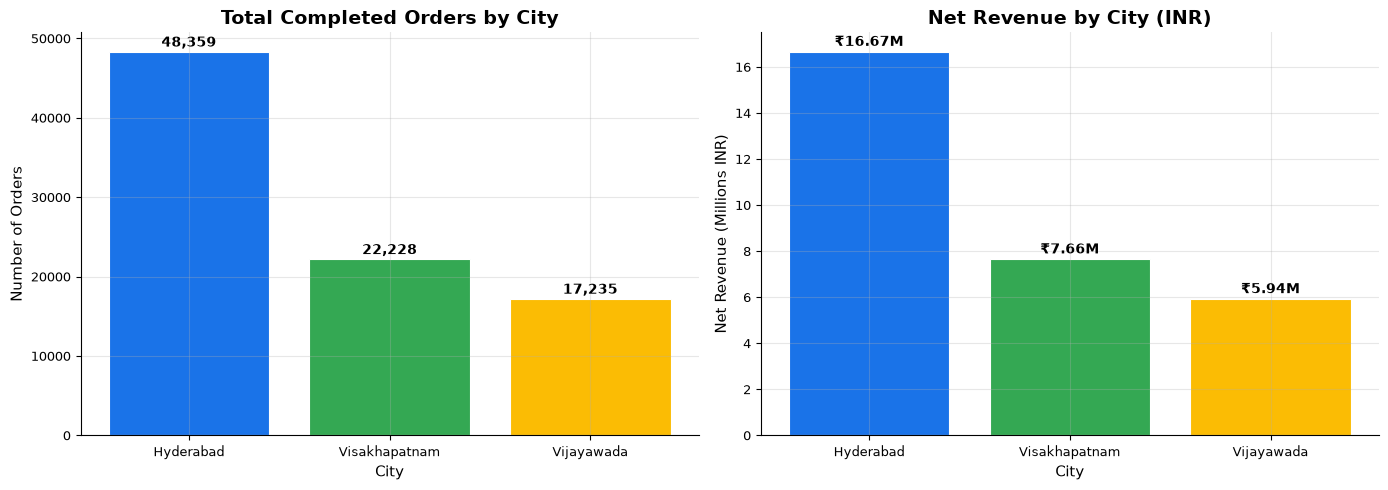

In [17]:
# Build master analytical dataframe
master = (orders
    .merge(restaurants[['restaurant_id','restaurant_name','cuisine','area','city']], on='restaurant_id')
    .merge(customers[['customer_id','city']], on='customer_id', suffixes=('_rest','_cust'))
)
master = master.merge(deliveries[['order_id','actual_delivery_minutes','delay_minutes',
                                   'delay_category','on_time_status','distance_km']],
                      on='order_id', how='left')
master = master.merge(feedback[['order_id','rating','complaint_type','refund_amount']],
                      on='order_id', how='left')

print(f"Master dataframe shape: {master.shape}")

city_orders = master[master['order_status'].isin(['Completed','Partially Delivered'])]
city_summary = city_orders.groupby('city_rest').agg(
    total_orders=('order_id','count'),
    gross_revenue=('order_value','sum'),
    net_revenue=('final_amount','sum')
).reset_index().sort_values('total_orders', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Orders by city
bars = axes[0].bar(city_summary['city_rest'], city_summary['total_orders'],
                   color=PALETTE[:3], edgecolor='white', linewidth=0.8)
axes[0].set_title('Total Completed Orders by City')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Number of Orders')
for bar, val in zip(bars, city_summary['total_orders']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# Revenue by city
bars2 = axes[1].bar(city_summary['city_rest'], city_summary['net_revenue']/1e6,
                    color=PALETTE[:3], edgecolor='white', linewidth=0.8)
axes[1].set_title('Net Revenue by City (INR)')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Net Revenue (Millions INR)')
for bar, val in zip(bars2, city_summary['net_revenue']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'\u20B9{val/1e6:.2f}M', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_01_city_orders_revenue.png'), dpi=150, bbox_inches='tight')
plt.show()

print("\n--- BUSINESS INSIGHT ---")
print("Hyderabad dominates both order volume and revenue, reflecting its larger population.")
print("Visakhapatnam shows strong per-order value despite lower volume.")
print("Action: Focus marketing investment on Hyderabad while growing Vizag and Vijayawada markets.")


### 11.2 Orders by Cuisine


--- BUSINESS INSIGHT ---
Biryani is the top-ordered cuisine, consistent with South Indian food preferences.
Pizza and North Indian also show strong performance.
Action: Partner with more Biryani-specialized restaurants in Hyderabad.


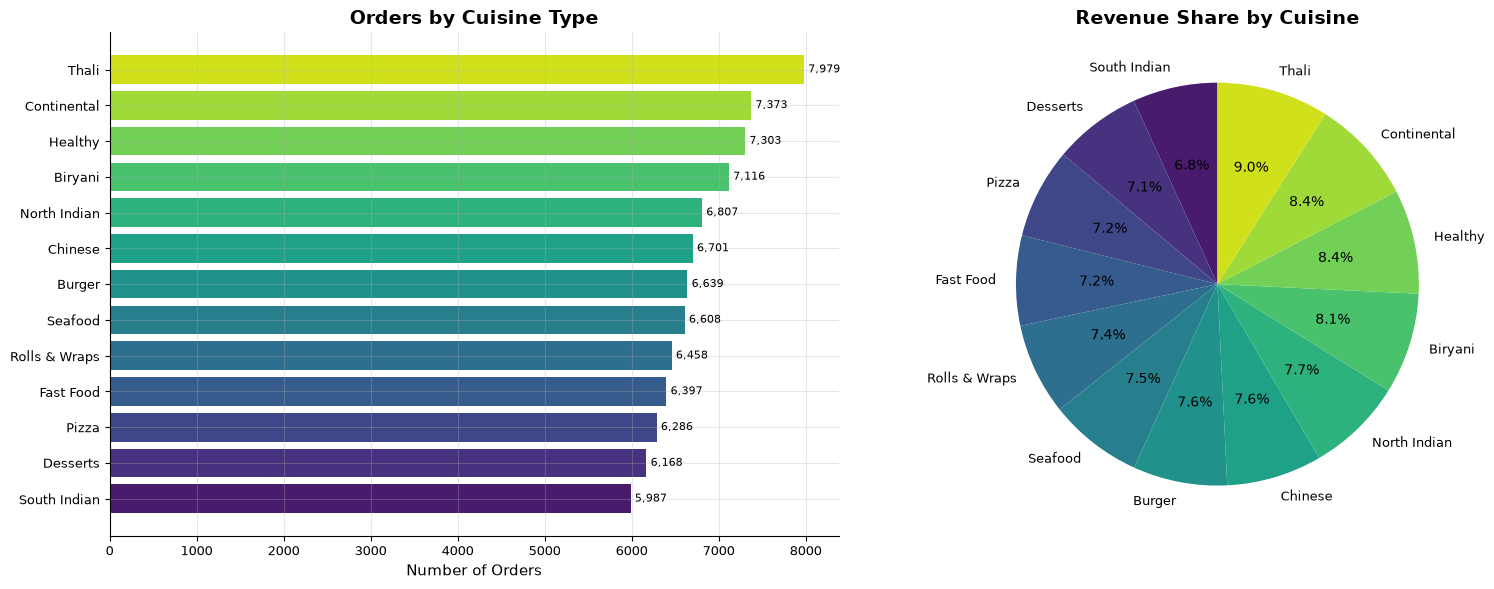

In [18]:
cuisine_data = (master[master['order_status'].isin(['Completed','Partially Delivered'])]
    .groupby('cuisine')
    .agg(orders=('order_id','count'), revenue=('final_amount','sum'),
         avg_rating=('rating','mean'))
    .reset_index()
    .sort_values('orders', ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Horizontal bar: orders by cuisine
axes[0].barh(cuisine_data['cuisine'], cuisine_data['orders'],
             color=sns.color_palette('viridis', len(cuisine_data)))
axes[0].set_title('Orders by Cuisine Type')
axes[0].set_xlabel('Number of Orders')
for i, (val, cuis) in enumerate(zip(cuisine_data['orders'], cuisine_data['cuisine'])):
    axes[0].text(val + 50, i, f'{val:,}', va='center', fontsize=8)

# Pie: revenue share
axes[1].pie(cuisine_data['revenue'], labels=cuisine_data['cuisine'],
            autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette('viridis', len(cuisine_data)))
axes[1].set_title('Revenue Share by Cuisine')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_02_cuisine.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Biryani is the top-ordered cuisine, consistent with South Indian food preferences.")
print("Pizza and North Indian also show strong performance.")
print("Action: Partner with more Biryani-specialized restaurants in Hyderabad.")


### 11.3 Average Delivery Time by City


--- BUSINESS INSIGHT ---
Average delivery times are comparable across all 3 cities (~46 min).
On-time rates are strong (>80%) overall.
Action: Focus delay reduction during peak hours in all cities.


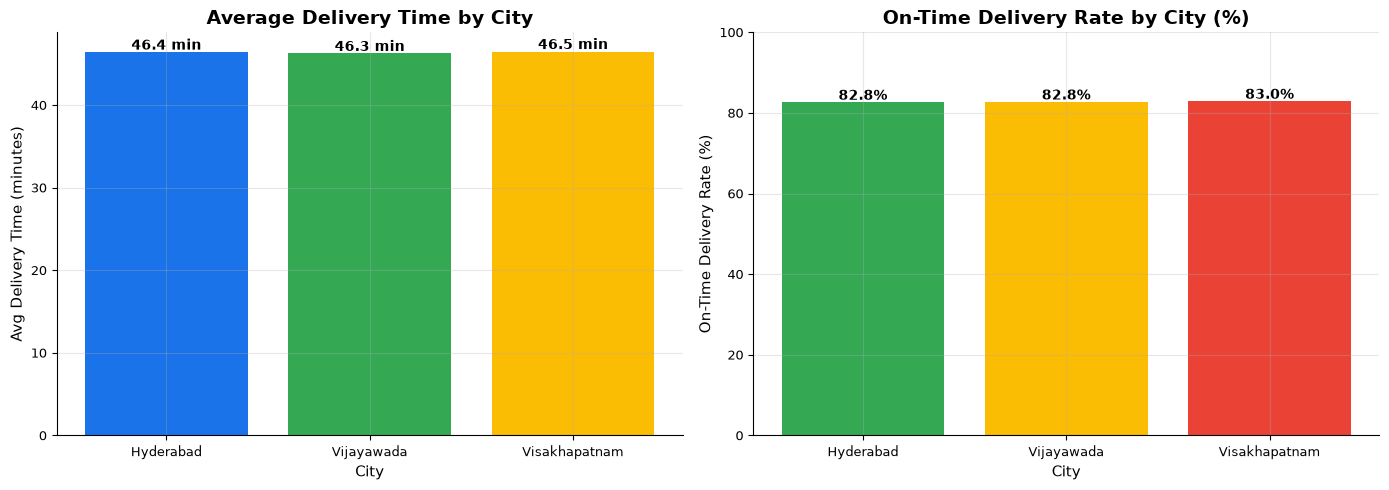

In [19]:
del_city = (master[master['actual_delivery_minutes'].notna()]
    .groupby('city_rest')
    .agg(avg_del=('actual_delivery_minutes','mean'),
         on_time_rate=('on_time_status', lambda x: (x=='On Time').mean()*100))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(del_city['city_rest'], del_city['avg_del'], color=PALETTE[:3])
axes[0].set_title('Average Delivery Time by City')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Avg Delivery Time (minutes)')
for i, (city, val) in enumerate(zip(del_city['city_rest'], del_city['avg_del'])):
    axes[0].text(i, val + 0.3, f'{val:.1f} min', ha='center', fontweight='bold')

axes[1].bar(del_city['city_rest'], del_city['on_time_rate'], color=PALETTE[1:4])
axes[1].set_title('On-Time Delivery Rate by City (%)')
axes[1].set_xlabel('City')
axes[1].set_ylabel('On-Time Delivery Rate (%)')
axes[1].set_ylim(0, 100)
for i, (city, val) in enumerate(zip(del_city['city_rest'], del_city['on_time_rate'])):
    axes[1].text(i, val + 0.5, f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_03_delivery_time_city.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Average delivery times are comparable across all 3 cities (~46 min).")
print("On-time rates are strong (>80%) overall.")
print("Action: Focus delay reduction during peak hours in all cities.")


### 11.4 Order Distribution by Hour (Peak Hour Analysis)


--- BUSINESS INSIGHT ---
Dinner peak (19-22h) has the highest order volume AND the highest cancellation rates.
Lunch peak (12-14h) shows a secondary spike.
Action: Increase rider availability during 19-22h. Streamline restaurant onboarding protocols.


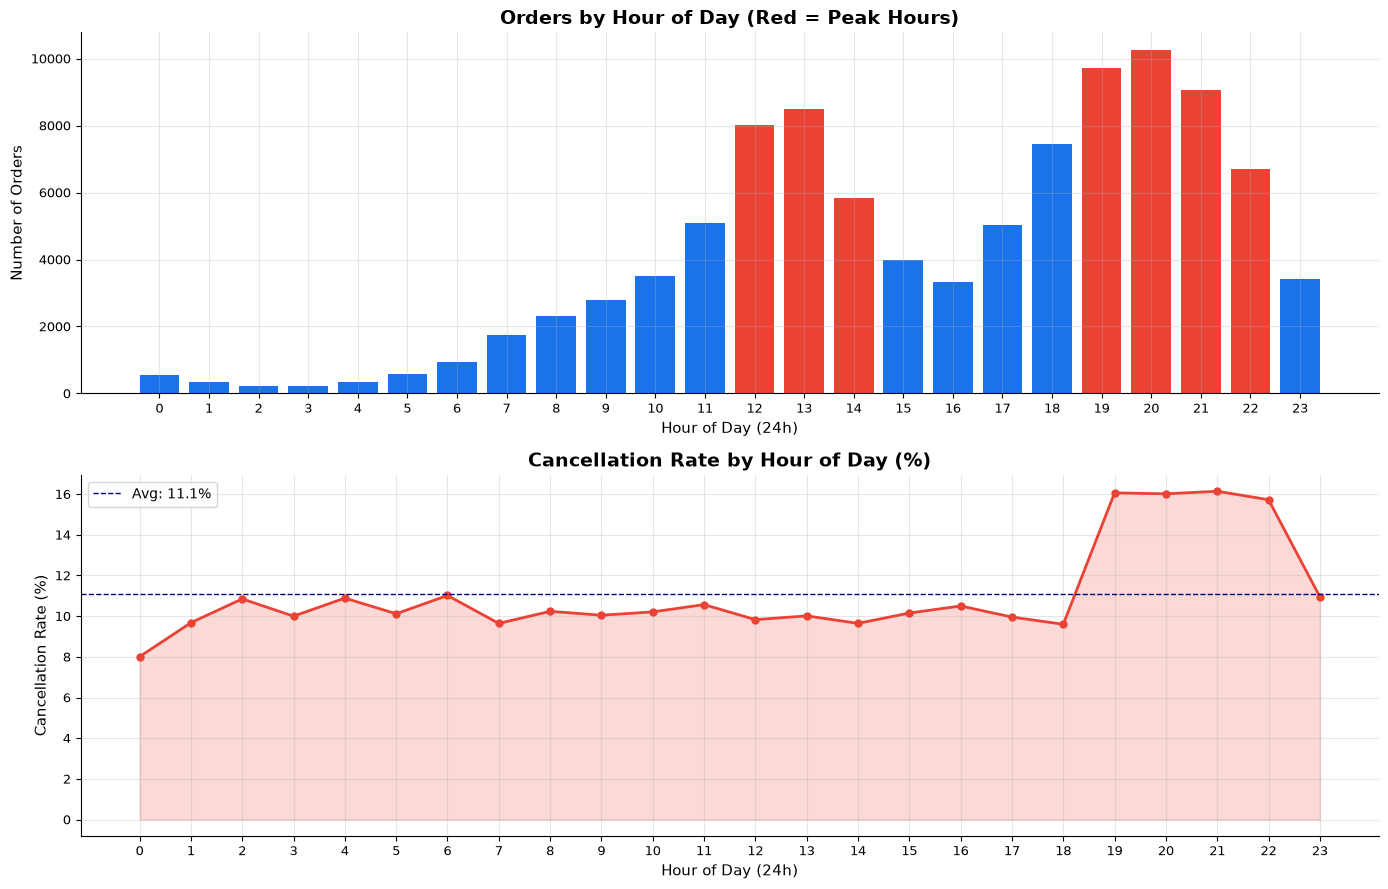

In [20]:
hourly = orders.groupby('order_hour').agg(
    total_orders=('order_id','count'),
    cancelled=('is_cancelled','sum')
).reset_index()
hourly['cancel_rate'] = hourly['cancelled'] / hourly['total_orders'] * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Order volume by hour
color_map = ['#EA4335' if h in [12,13,14,19,20,21,22] else '#1A73E8'
             for h in hourly['order_hour']]
axes[0].bar(hourly['order_hour'], hourly['total_orders'], color=color_map)
axes[0].set_title('Orders by Hour of Day (Red = Peak Hours)')
axes[0].set_xlabel('Hour of Day (24h)')
axes[0].set_ylabel('Number of Orders')
axes[0].set_xticks(range(24))

# Cancellation rate by hour
axes[1].plot(hourly['order_hour'], hourly['cancel_rate'],
             color='#EA4335', linewidth=2, marker='o', markersize=5)
axes[1].fill_between(hourly['order_hour'], hourly['cancel_rate'], alpha=0.2, color='#EA4335')
axes[1].set_title('Cancellation Rate by Hour of Day (%)')
axes[1].set_xlabel('Hour of Day (24h)')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].set_xticks(range(24))
axes[1].axhline(hourly['cancel_rate'].mean(), color='navy', linestyle='--', linewidth=1,
                label=f"Avg: {hourly['cancel_rate'].mean():.1f}%")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_04_hourly_orders.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Dinner peak (19-22h) has the highest order volume AND the highest cancellation rates.")
print("Lunch peak (12-14h) shows a secondary spike.")
print("Action: Increase rider availability during 19-22h. Streamline restaurant onboarding protocols.")


### 11.5 Delivery Delays by Area


--- BUSINESS INSIGHT ---
Several areas show consistently above-average delivery delays.
These are likely high-traffic or distant zones with inadequate rider coverage.
Action: Deploy additional riders in high-delay areas, especially during peak hours.


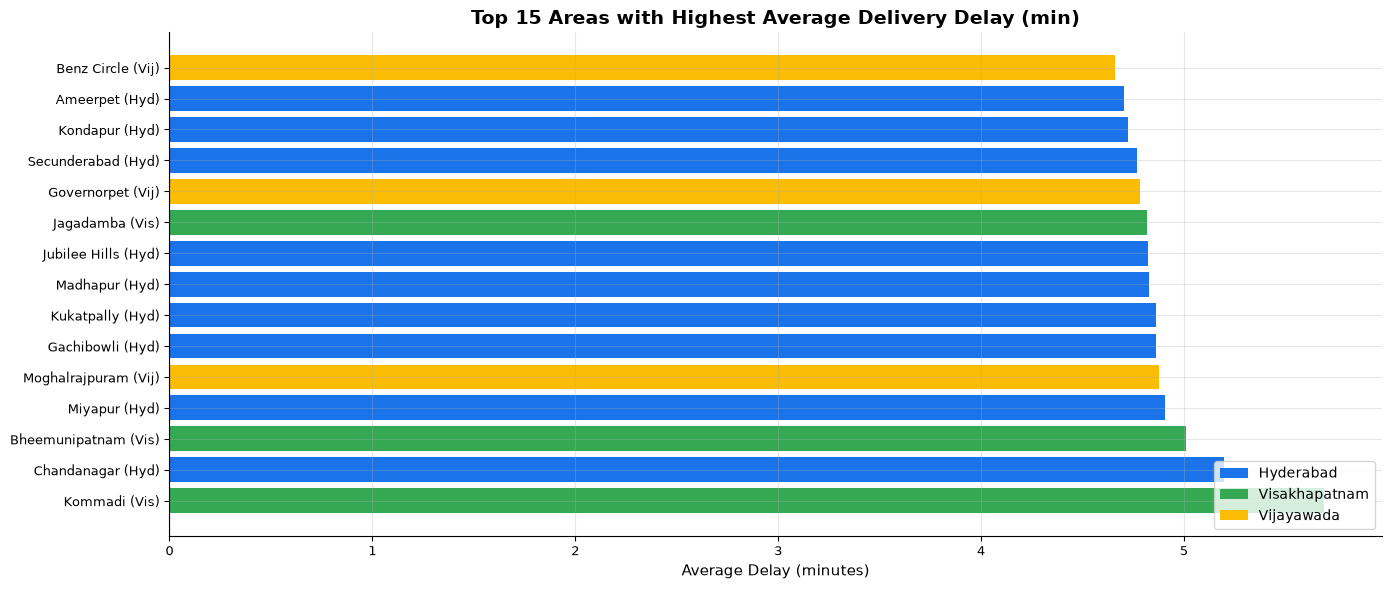

In [21]:
area_delays = (master[master['delay_minutes'].notna()]
    .groupby(['city_rest','area'])
    .agg(avg_delay=('delay_minutes','mean'),
         total_deliveries=('delivery_id' if 'delivery_id' in master.columns else 'order_id','count'))
    .reset_index()
    .query('total_deliveries >= 50')
    .sort_values('avg_delay', ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(14, 6))
CITIES_LIST = ['Hyderabad', 'Visakhapatnam', 'Vijayawada']
city_colors = {c: PALETTE[i] for i, c in enumerate(CITIES_LIST)}
colors = [city_colors.get(c, '#9AA0A6') for c in area_delays['city_rest']]

bars = ax.barh(area_delays['area'] + ' (' + area_delays['city_rest'].str[:3] + ')',
               area_delays['avg_delay'], color=colors)
ax.set_title('Top 15 Areas with Highest Average Delivery Delay (min)')
ax.set_xlabel('Average Delay (minutes)')
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')

# Legend for cities
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=city_colors[c], label=c) for c in CITIES_LIST]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_05_area_delays.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Several areas show consistently above-average delivery delays.")
print("These are likely high-traffic or distant zones with inadequate rider coverage.")
print("Action: Deploy additional riders in high-delay areas, especially during peak hours.")


### 11.6 Ratings Distribution


--- BUSINESS INSIGHT ---
Average rating: 3.71 / 5.0
% of 4-5 star reviews: 64.1%
% of 1-2 star reviews: 6.2%

Action: Target restaurants with high 1-2 star rates for quality improvement programs.


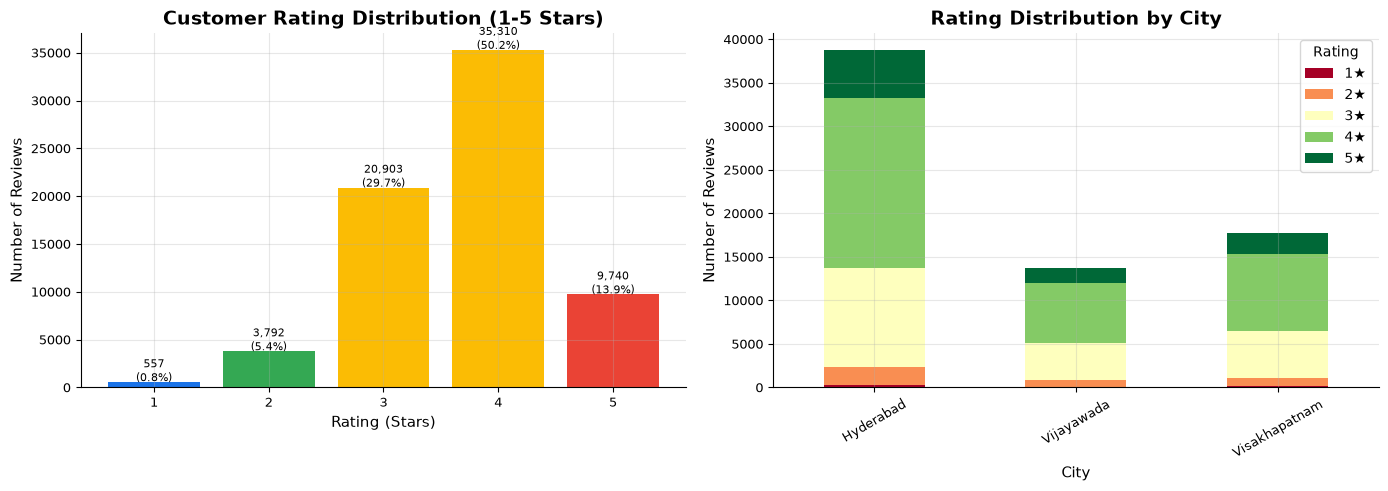

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Rating distribution
rating_counts = feedback['rating'].value_counts().sort_index()
colors_rating = ['#EA4335','#FBBC04','#FBBC04','#34A853','#1A73E8']
bars = axes[0].bar(rating_counts.index, rating_counts.values, color=colors_rating[::-1])
axes[0].set_title('Customer Rating Distribution (1-5 Stars)')
axes[0].set_xlabel('Rating (Stars)')
axes[0].set_ylabel('Number of Reviews')
axes[0].set_xticks([1,2,3,4,5])
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{val:,}\n({val/len(feedback)*100:.1f}%)',
                 ha='center', fontsize=8)

# Rating by city
rat_city = (master[master['rating'].notna()]
    .groupby('city_rest')['rating']
    .value_counts()
    .unstack()
    .reindex(columns=[1,2,3,4,5])
    .fillna(0)
)
rat_city.plot(kind='bar', ax=axes[1], colormap='RdYlGn', stacked=True)
axes[1].set_title('Rating Distribution by City')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Number of Reviews')
axes[1].legend(title='Rating', loc='upper right', labels=['1★','2★','3★','4★','5★'])
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_06_ratings.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"\n--- BUSINESS INSIGHT ---")
print(f"Average rating: {feedback['rating'].mean():.2f} / 5.0")
print(f"% of 4-5 star reviews: {(feedback['rating'] >= 4).mean()*100:.1f}%")
print(f"% of 1-2 star reviews: {(feedback['rating'] <= 2).mean()*100:.1f}%")
print("\nAction: Target restaurants with high 1-2 star rates for quality improvement programs.")


### 11.7 Delivery Delay vs Customer Rating


--- BUSINESS INSIGHT ---
Clear negative correlation: Higher delays consistently produce lower ratings.
'Severe Delay' orders average significantly lower ratings than 'Early' deliveries.
Action: Every 10-minute reduction in delivery time can measurably improve ratings.


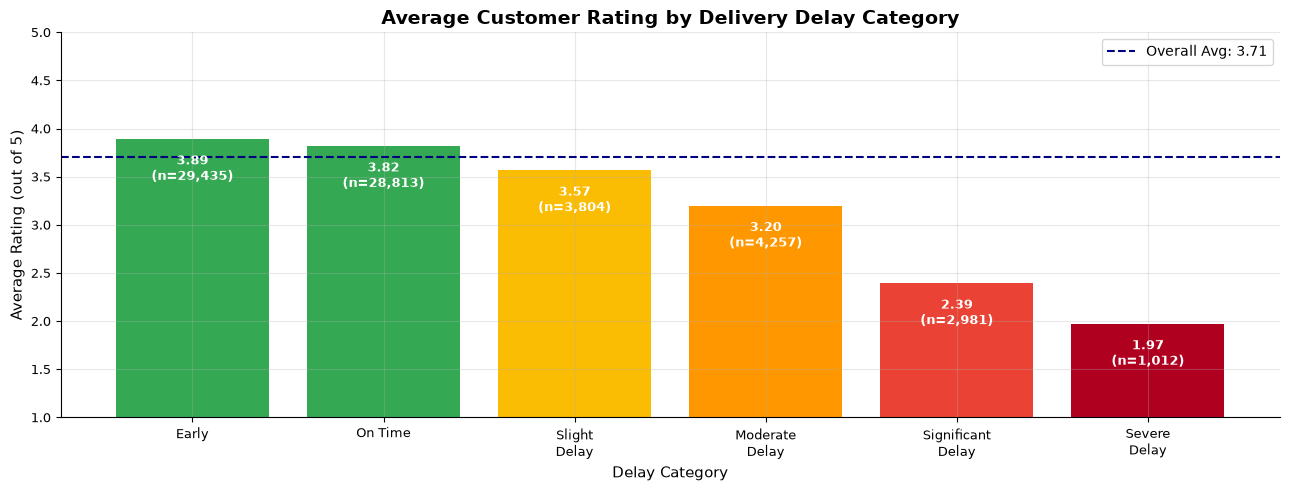

In [23]:
delay_rating = (master[master['delay_minutes'].notna() & master['rating'].notna()]
    .assign(delay_bucket=lambda df: pd.cut(
        df['delay_minutes'],
        bins=[-np.inf, 0, 5, 15, 30, 60, np.inf],
        labels=['Early', 'On Time', 'Slight\nDelay', 'Moderate\nDelay',
                'Significant\nDelay', 'Severe\nDelay']
    ))
    .groupby('delay_bucket')
    .agg(avg_rating=('rating','mean'), count=('rating','count'))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(delay_rating['delay_bucket'], delay_rating['avg_rating'],
              color=['#34A853','#34A853','#FBBC04','#FF9800','#EA4335','#B00020'])
ax.set_title('Average Customer Rating by Delivery Delay Category')
ax.set_xlabel('Delay Category')
ax.set_ylabel('Average Rating (out of 5)')
ax.set_ylim(1, 5)
ax.axhline(feedback['rating'].mean(), color='navy', linestyle='--', linewidth=1.5,
           label=f"Overall Avg: {feedback['rating'].mean():.2f}")
ax.legend()
for bar, (_, row) in zip(bars, delay_rating.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 0.15,
            f'{row.avg_rating:.2f}\n(n={int(row["count"]):,})',
            ha='center', va='top', fontsize=9, color='white', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_07_delay_vs_rating.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Clear negative correlation: Higher delays consistently produce lower ratings.")
print("'Severe Delay' orders average significantly lower ratings than 'Early' deliveries.")
print("Action: Every 10-minute reduction in delivery time can measurably improve ratings.")


### 11.8 Cancellation Rates by Restaurant (Top 20 Worst)


--- BUSINESS INSIGHT ---
The highest-cancellation restaurants should be reviewed for operational issues.
Possible causes: consistently unavailable items, long prep times, or payment failures.
Action: Auto-flag restaurants exceeding 20% cancellation rate for intervention.


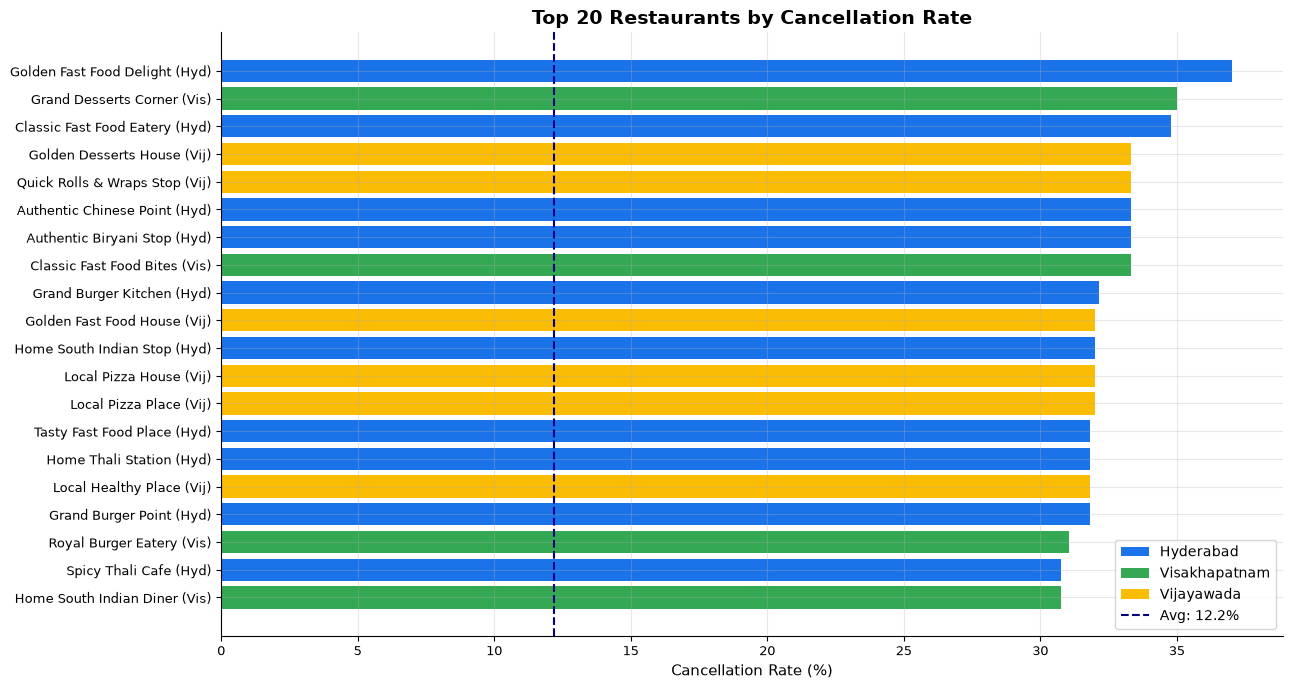

In [24]:
cancel_rest = (master
    .groupby(['restaurant_id','restaurant_name','city_rest'])
    .agg(total=('order_id','count'),
         cancelled=('is_cancelled','sum'))
    .reset_index()
    .query('total >= 20')
    .assign(cancel_rate=lambda df: df['cancelled']/df['total']*100)
    .sort_values('cancel_rate', ascending=True)
    .tail(20)
)

fig, ax = plt.subplots(figsize=(13, 7))
colors = [city_colors.get(c, '#9AA0A6') for c in cancel_rest['city_rest']]
ax.barh(cancel_rest['restaurant_name'] + ' (' + cancel_rest['city_rest'].str[:3] + ')',
        cancel_rest['cancel_rate'], color=colors)
ax.set_title('Top 20 Restaurants by Cancellation Rate')
ax.set_xlabel('Cancellation Rate (%)')
ax.axvline(master['is_cancelled'].mean()*100, color='navy', linestyle='--', linewidth=1.5,
           label=f"Avg: {master['is_cancelled'].mean()*100:.1f}%")
ax.legend()
legend_elements = [Patch(facecolor=city_colors[c], label=c) for c in CITIES_LIST]
ax.legend(handles=legend_elements + [
    plt.Line2D([0],[0],color='navy',linestyle='--',
               label=f"Avg: {master['is_cancelled'].mean()*100:.1f}%")], loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_08_cancellation_rates.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("The highest-cancellation restaurants should be reviewed for operational issues.")
print("Possible causes: consistently unavailable items, long prep times, or payment failures.")
print("Action: Auto-flag restaurants exceeding 20% cancellation rate for intervention.")


### 11.9 Distance vs Delivery Time


--- BUSINESS INSIGHT ---
Pearson correlation (distance vs delivery time): 0.642
Positive correlation confirms: longer distances = longer deliveries.
Action: Implement zone-based SLA targets instead of one-size-fits-all delivery promises.


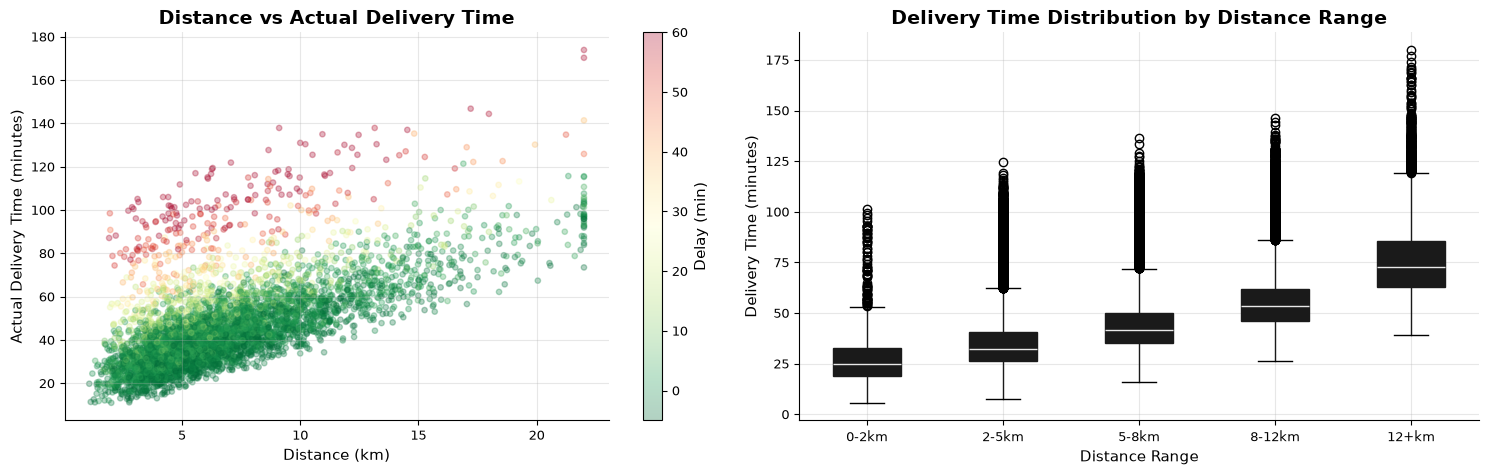

In [25]:
dist_del = master[master['actual_delivery_minutes'].notna() & master['distance_km'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scatter plot: sample 5000 points for readability
sample = dist_del.sample(min(5000, len(dist_del)), random_state=42)
scatter = axes[0].scatter(sample['distance_km'], sample['actual_delivery_minutes'],
                          alpha=0.3, c=sample['delay_minutes'], cmap='RdYlGn_r',
                          vmin=-5, vmax=60, s=15)
axes[0].set_title('Distance vs Actual Delivery Time')
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Actual Delivery Time (minutes)')
plt.colorbar(scatter, ax=axes[0], label='Delay (min)')

# Box plot by distance bucket
dist_del['dist_bucket'] = pd.cut(dist_del['distance_km'],
                                  bins=[0,2,5,8,12,25],
                                  labels=['0-2km','2-5km','5-8km','8-12km','12+km'])
dist_del.boxplot(column='actual_delivery_minutes', by='dist_bucket', ax=axes[1],
                 patch_artist=True)
axes[1].set_title('Delivery Time Distribution by Distance Range')
axes[1].set_xlabel('Distance Range')
axes[1].set_ylabel('Delivery Time (minutes)')
plt.suptitle('')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_09_distance_vs_time.png'), dpi=150, bbox_inches='tight')
plt.show()
corr = dist_del['distance_km'].corr(dist_del['actual_delivery_minutes'])
print(f"\n--- BUSINESS INSIGHT ---")
print(f"Pearson correlation (distance vs delivery time): {corr:.3f}")
print("Positive correlation confirms: longer distances = longer deliveries.")
print("Action: Implement zone-based SLA targets instead of one-size-fits-all delivery promises.")


### 11.10 Restaurant Preparation Time vs Delivery Delay


--- BUSINESS INSIGHT ---
Correlation (prep time vs delay): -0.010
Restaurants with longer prep times show slightly higher delays.
Action: Set realistic estimated delivery times for slow-prep cuisines (Biryani, Seafood).


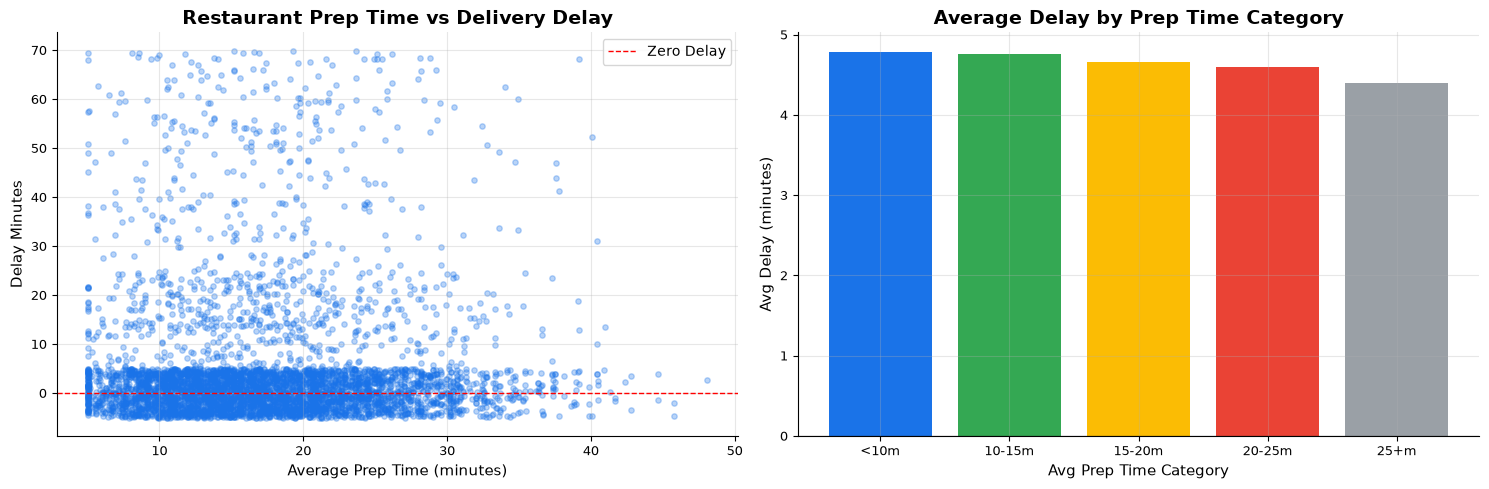

In [26]:
prep_delay = (master[master['delay_minutes'].notna()]
    .merge(restaurants[['restaurant_id','avg_prep_time']], on='restaurant_id', how='left')
    .dropna(subset=['avg_prep_time','delay_minutes'])
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sample2 = prep_delay.sample(min(5000, len(prep_delay)), random_state=42)
axes[0].scatter(sample2['avg_prep_time'], sample2['delay_minutes'],
                alpha=0.3, color='#1A73E8', s=15)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1, label='Zero Delay')
axes[0].set_title('Restaurant Prep Time vs Delivery Delay')
axes[0].set_xlabel('Average Prep Time (minutes)')
axes[0].set_ylabel('Delay Minutes')
axes[0].legend()

prep_delay['prep_bucket'] = pd.cut(prep_delay['avg_prep_time'],
                                    bins=[0,10,15,20,25,50],
                                    labels=['<10m','10-15m','15-20m','20-25m','25+m'])
prep_bucket_delay = (prep_delay
    .groupby('prep_bucket')['delay_minutes']
    .mean()
    .reset_index()
)
axes[1].bar(prep_bucket_delay['prep_bucket'], prep_bucket_delay['delay_minutes'],
            color=PALETTE[:5])
axes[1].set_title('Average Delay by Prep Time Category')
axes[1].set_xlabel('Avg Prep Time Category')
axes[1].set_ylabel('Avg Delay (minutes)')
axes[1].axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_10_prep_vs_delay.png'), dpi=150, bbox_inches='tight')
plt.show()
corr2 = prep_delay['avg_prep_time'].corr(prep_delay['delay_minutes'])
print(f"\n--- BUSINESS INSIGHT ---")
print(f"Correlation (prep time vs delay): {corr2:.3f}")
print("Restaurants with longer prep times show slightly higher delays.")
print("Action: Set realistic estimated delivery times for slow-prep cuisines (Biryani, Seafood).")


### 11.11 Repeat vs One-Time Customers


--- BUSINESS INSIGHT ---
One-time customers: 13.5% of customer base
Loyal customers (10+ orders): 13.8% of customer base
Despite being a small %, loyal customers drive a disproportionate share of revenue.
Action: Implement loyalty programs (discount tiers, free delivery) to convert one-timers.


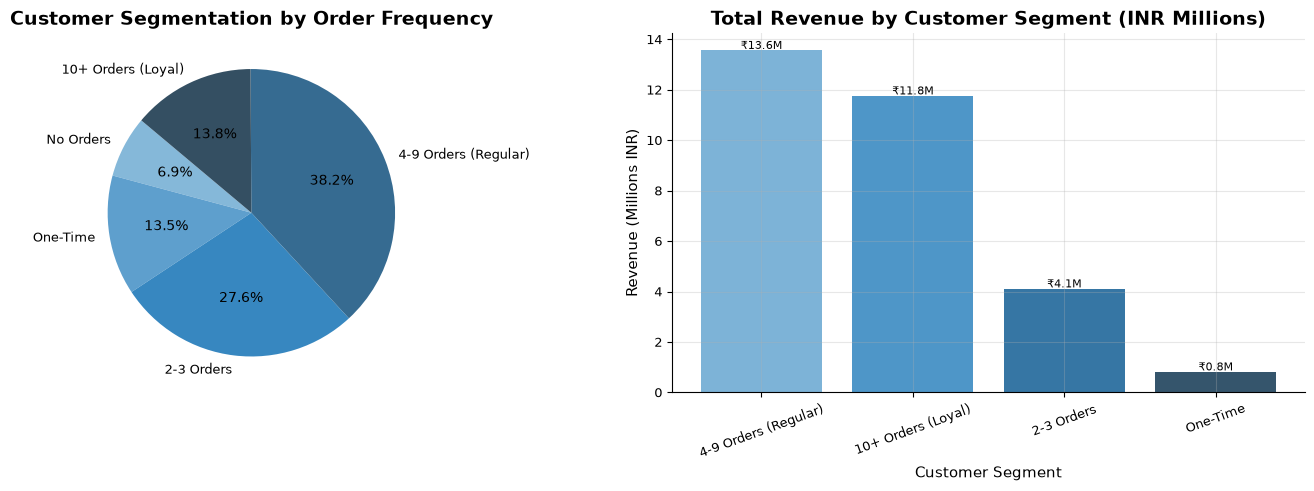

In [27]:
seg_summary = (customers
    .groupby('customer_segment')
    .agg(count=('customer_id','count'))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
wedges, texts, autotexts = axes[0].pie(
    seg_summary['count'],
    labels=seg_summary['customer_segment'],
    autopct='%1.1f%%',
    colors=sns.color_palette('Blues_d', len(seg_summary)),
    startangle=140
)
axes[0].set_title('Customer Segmentation by Order Frequency')

# Bar chart of customer revenue contribution
seg_revenue = (master[master['order_status'].isin(['Completed','Partially Delivered'])]
    .merge(customers[['customer_id','customer_segment']], on='customer_id', how='left')
    .groupby('customer_segment')
    .agg(revenue=('final_amount','sum'), orders=('order_id','count'))
    .reset_index()
    .sort_values('revenue', ascending=False)
)
bars = axes[1].bar(seg_revenue['customer_segment'], seg_revenue['revenue']/1e6,
                   color=sns.color_palette('Blues_d', len(seg_revenue)))
axes[1].set_title('Total Revenue by Customer Segment (INR Millions)')
axes[1].set_xlabel('Customer Segment')
axes[1].set_ylabel('Revenue (Millions INR)')
axes[1].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, seg_revenue['revenue']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'\u20B9{val/1e6:.1f}M', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_11_customer_segments.png'), dpi=150, bbox_inches='tight')
plt.show()
one_time_pct = (customers['customer_segment']=='One-Time').mean()*100
loyal_pct    = (customers['customer_segment']=='10+ Orders (Loyal)').mean()*100
print(f"\n--- BUSINESS INSIGHT ---")
print(f"One-time customers: {one_time_pct:.1f}% of customer base")
print(f"Loyal customers (10+ orders): {loyal_pct:.1f}% of customer base")
print("Despite being a small %, loyal customers drive a disproportionate share of revenue.")
print("Action: Implement loyalty programs (discount tiers, free delivery) to convert one-timers.")


### 11.12 Customer Complaints by Category


--- BUSINESS INSIGHT ---
Top 3 complaint types:
  Missing Item        : 3,313 (4.7% of all feedback)
  Rude Rider          : 3,312 (4.7% of all feedback)
  Wrong Item          : 3,258 (4.6% of all feedback)

Action: 'Late Delivery' and 'Cold Food' are operationally fixable through better
insulation packaging and route optimization. Prioritize these in next sprint.


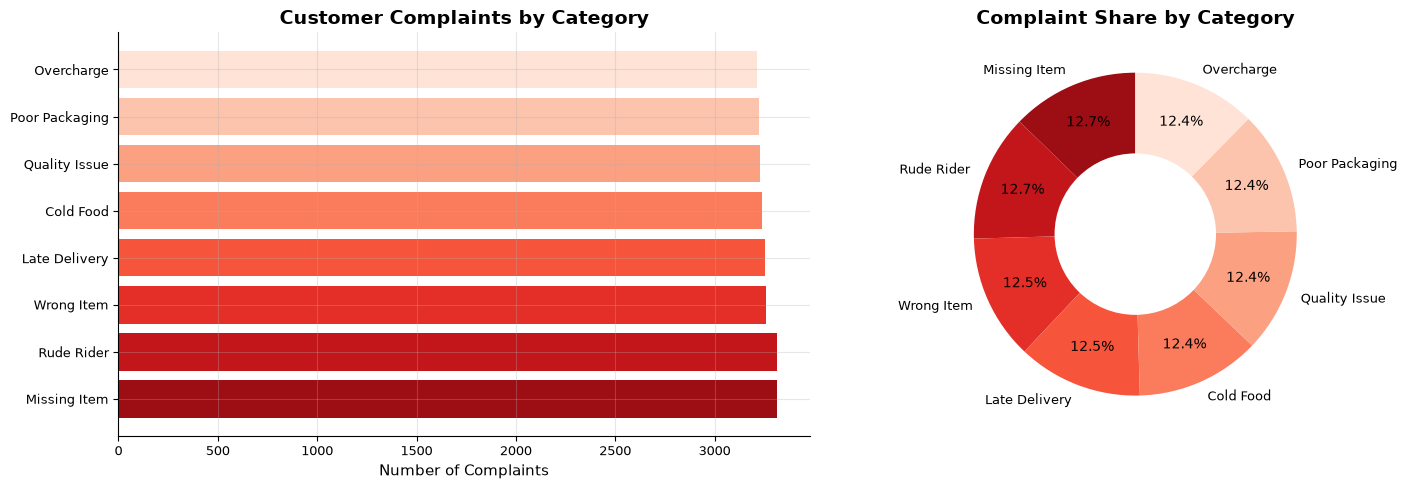

In [28]:
complaint_df = (feedback[
    feedback['complaint_type'].notna() & (feedback['complaint_type'] != '')
]['complaint_type'].value_counts().reset_index()
)
complaint_df.columns = ['complaint_type','count']
complaint_df['pct'] = complaint_df['count'] / len(feedback) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Horizontal bar
colors_c = sns.color_palette('Reds_r', len(complaint_df))
axes[0].barh(complaint_df['complaint_type'], complaint_df['count'], color=colors_c)
axes[0].set_title('Customer Complaints by Category')
axes[0].set_xlabel('Number of Complaints')

# Donut chart
wedges, texts, autotexts = axes[1].pie(
    complaint_df['count'],
    labels=complaint_df['complaint_type'],
    autopct='%1.1f%%',
    colors=colors_c,
    startangle=90,
    pctdistance=0.75
)
centre_circle = plt.Circle((0,0), 0.50, fc='white')
axes[1].add_patch(centre_circle)
axes[1].set_title('Complaint Share by Category')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_12_complaints.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Top 3 complaint types:")
for _, row in complaint_df.head(3).iterrows():
    print(f"  {row['complaint_type']:20s}: {row['count']:,} ({row['pct']:.1f}% of all feedback)")
print("\nAction: 'Late Delivery' and 'Cold Food' are operationally fixable through better")
print("insulation packaging and route optimization. Prioritize these in next sprint.")


### 11.13 Revenue and Order Trends Over Time


--- BUSINESS INSIGHT ---
Order volumes show seasonal patterns with peaks in certain months.
Rating trends reveal whether service quality is improving or declining over time.
Action: Correlate dips in ratings with operational changes or seasonal pressure.


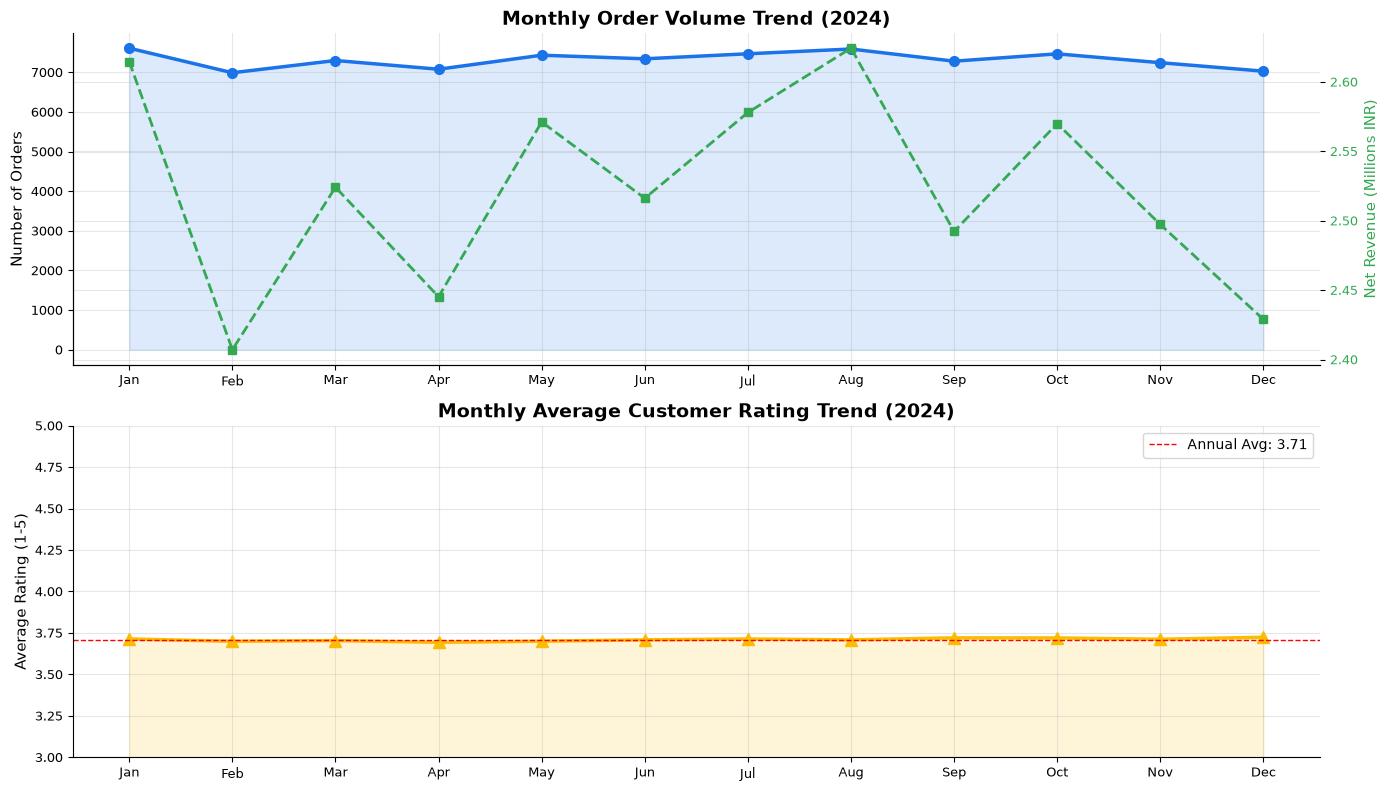

In [29]:
monthly = (master[master['order_status'].isin(['Completed','Partially Delivered'])]
    .groupby('order_month')
    .agg(orders=('order_id','count'),
         revenue=('final_amount','sum'),
         avg_rating=('rating','mean'))
    .reset_index()
)
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly['month_name'] = [month_names[m-1] for m in monthly['order_month']]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Orders trend
axes[0].plot(monthly['month_name'], monthly['orders'], color='#1A73E8',
             linewidth=2.5, marker='o', markersize=7)
axes[0].fill_between(range(len(monthly)), monthly['orders'], alpha=0.15, color='#1A73E8')
axes[0].set_title('Monthly Order Volume Trend (2024)')
axes[0].set_ylabel('Number of Orders')
axes[0].set_xticks(range(len(monthly)))
axes[0].set_xticklabels(monthly['month_name'])

# Revenue trend
ax2 = axes[0].twinx()
ax2.plot(monthly['month_name'], monthly['revenue']/1e6, color='#34A853',
         linewidth=2, linestyle='--', marker='s', markersize=6, label='Revenue')
ax2.set_ylabel('Net Revenue (Millions INR)', color='#34A853')
ax2.tick_params(axis='y', labelcolor='#34A853')

# Rating trend
axes[1].plot(monthly['month_name'], monthly['avg_rating'], color='#FBBC04',
             linewidth=2.5, marker='^', markersize=8)
axes[1].fill_between(range(len(monthly)), monthly['avg_rating'], alpha=0.15, color='#FBBC04')
axes[1].set_title('Monthly Average Customer Rating Trend (2024)')
axes[1].set_ylabel('Average Rating (1-5)')
axes[1].set_ylim(3.0, 5.0)
axes[1].set_xticks(range(len(monthly)))
axes[1].set_xticklabels(monthly['month_name'])
axes[1].axhline(monthly['avg_rating'].mean(), color='red', linestyle='--', linewidth=1,
                label=f"Annual Avg: {monthly['avg_rating'].mean():.2f}")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_13_trends.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n--- BUSINESS INSIGHT ---")
print("Order volumes show seasonal patterns with peaks in certain months.")
print("Rating trends reveal whether service quality is improving or declining over time.")
print("Action: Correlate dips in ratings with operational changes or seasonal pressure.")


### 11.14 Refund Analysis by City


--- BUSINESS INSIGHT ---
Total refund exposure: INR 340,748
Refunds are concentrated in low-rated orders with complaints.
Action: Proactive quality monitoring can reduce refund exposure significantly.


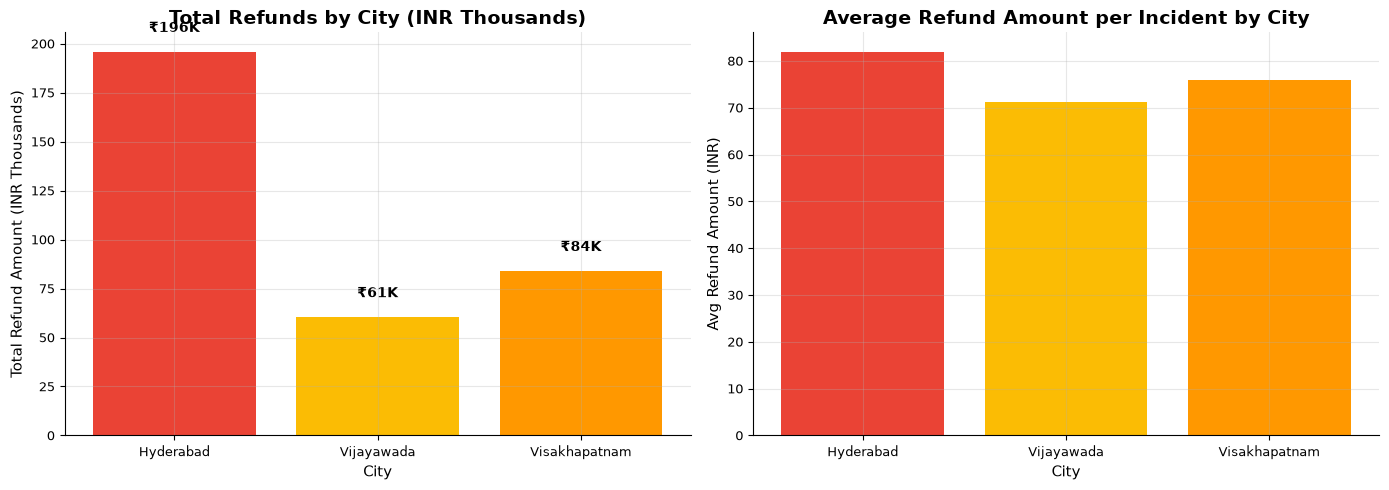

In [30]:
refund_city = (master[master['refund_amount'].notna() & (master['refund_amount'] > 0)]
    .groupby('city_rest')
    .agg(total_refunds=('refund_amount','sum'),
         refund_count=('refund_amount','count'),
         avg_refund=('refund_amount','mean'))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(refund_city['city_rest'], refund_city['total_refunds']/1000,
            color=['#EA4335','#FBBC04','#FF9800'])
axes[0].set_title('Total Refunds by City (INR Thousands)')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Total Refund Amount (INR Thousands)')
for i, (c, val) in enumerate(zip(refund_city['city_rest'], refund_city['total_refunds'])):
    axes[0].text(i, val/1000 + 10, f'\u20B9{val/1000:.0f}K', ha='center', fontweight='bold')

axes[1].bar(refund_city['city_rest'], refund_city['avg_refund'],
            color=['#EA4335','#FBBC04','#FF9800'])
axes[1].set_title('Average Refund Amount per Incident by City')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Avg Refund Amount (INR)')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'docs', 'viz_14_refunds.png'), dpi=150, bbox_inches='tight')
plt.show()
total_refund = master['refund_amount'].sum()
print(f"\n--- BUSINESS INSIGHT ---")
print(f"Total refund exposure: INR {total_refund:,.0f}")
print("Refunds are concentrated in low-rated orders with complaints.")
print("Action: Proactive quality monitoring can reduce refund exposure significantly.")


### 11.15 Summary Statistics Dashboard

In [31]:
# Final KPI Summary
print("=" * 55)
print("  QUICKBITE ANALYTICS — KPI SUMMARY DASHBOARD")
print("=" * 55)
total_orders    = len(orders)
completed       = (orders['order_status'].isin(['Completed','Partially Delivered'])).sum()
cancelled       = orders['order_status'].isin(['Cancelled','Refunded']).sum()
cancel_rate     = cancelled / total_orders * 100
gross_rev       = orders.loc[orders['order_status'].isin(['Completed','Partially Delivered']),'order_value'].sum()
net_rev         = orders.loc[orders['order_status'].isin(['Completed','Partially Delivered']),'final_amount'].sum()
avg_del_time    = deliveries['actual_delivery_minutes'].mean()
on_time_rate    = (deliveries['on_time_status']=='On Time').mean() * 100
avg_rating      = feedback['rating'].mean()
repeat_rate     = (customers['customer_segment'].isin(['2-3 Orders','4-9 Orders (Regular)','10+ Orders (Loyal)'])).mean() * 100
total_refund    = feedback['refund_amount'].sum()

kpis = [
    ('Total Orders',          f'{total_orders:,}'),
    ('Completed Orders',      f'{completed:,}'),
    ('Gross Revenue',         f'INR {gross_rev:,.0f}'),
    ('Net Revenue',           f'INR {net_rev:,.0f}'),
    ('Cancellation Rate',     f'{cancel_rate:.2f}%'),
    ('Avg Delivery Time',     f'{avg_del_time:.1f} min'),
    ('On-Time Delivery Rate', f'{on_time_rate:.1f}%'),
    ('Average Customer Rating',f'{avg_rating:.2f} / 5.0'),
    ('Repeat Customer Rate',  f'{repeat_rate:.1f}%'),
    ('Total Refunds Issued',  f'INR {total_refund:,.0f}'),
]

for kpi, val in kpis:
    print(f"  {kpi:30s}: {val}")
print("=" * 55)
print("\n Analysis complete! All visualizations saved to docs/")


  QUICKBITE ANALYTICS — KPI SUMMARY DASHBOARD
  Total Orders                  : 100,000
  Completed Orders              : 87,822
  Gross Revenue                 : INR 32,878,779
  Net Revenue                   : INR 30,268,639
  Cancellation Rate             : 12.18%
  Avg Delivery Time             : 46.4 min
  On-Time Delivery Rate         : 82.8%
  Average Customer Rating       : 3.71 / 5.0
  Repeat Customer Rate          : 79.6%
  Total Refunds Issued          : INR 340,748

 Analysis complete! All visualizations saved to docs/
